# 모의고사 1회 · 통신사 고객 이탈(Churn) 예측
AICE 2주 합격 플랜 · 영상 11편. 공식 샘플(분류형)과 같은 구조의 14문항입니다. **90분 타이머를 켜고** 시험처럼 푸세요.
- 도메인: 통신 서비스 · 목표: 이탈할 고객을 미리 찾는 모델 만들기
- 문항에 변수명이 주어지면 반드시 그 이름을 쓰세요. 빈칸 문제는 빈칸에 들어갈 말을 답안 변수에 **문자열로** 저장하세요. 준비 칸에 없는 도구는 답 칸에서 직접 import 하세요.

| 컬럼 | 설명 |
|---|---|
| CustomerID | 고객 번호 |
| Churn | 이탈 여부 (Yes, No) |
| Gender | 성별 |
| SeniorCitizen | 65세 이상 여부 (1, 0) |
| Tenure | 가입 기간(개월) |
| Contract | 계약 형태 |
| InternetService | 인터넷 서비스 |
| PaymentMethod | 결제 방법 |
| MonthlyCharges | 월 요금 |
| TotalCharges | 누적 요금 |
| SupportCalls | 고객센터 상담 횟수 |

_최종 수정 2026-10-20 · 바뀐 내용은 [안내 페이지의 업데이트 기록](https://pm-ainote.github.io/aice/#updates) · 개인 학습용, 재배포·판매 금지_

### 준비: 데이터 내려받기
아래 셀을 먼저 실행하세요.

In [1]:
!wget -q -O mock1_churn.csv https://raw.githubusercontent.com/pm-ainote/aice/main/data/mock1_churn.csv
import os
print('준비 완료' if os.path.exists('mock1_churn.csv') and os.path.getsize('mock1_churn.csv') > 0 else '내려받기 실패: 이 셀을 다시 실행하세요')

준비 완료


## <데이터 분석>
### 1. scikit-learn 을 별칭 sk 로 불러오세요

In [2]:
import sklearn as sk

### 다음 문항을 풀기 전에 아래 코드를 실행하세요.

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

### 2. mock1_churn.csv 를 읽어 데이터프레임 변수명 `data` 에 할당하고 첫 5개 행을 출력하세요

In [7]:
data = pd.read_csv('mock1_churn.csv')
data.head(5)

,CustomerID,Churn,Gender,SeniorCitizen,Tenure,Contract,InternetService,PaymentMethod,MonthlyCharges,TotalCharges,SupportCalls
0,C100000,No,Male,0,42,Two year,Fiber optic,Card,104.95,4538.94,1
1,C100001,Yes,Male,0,44,Month-to-month,No,Bank transfer|Auto,18.00,773.03,3
2,C100002,No,Female,0,49,One year,DSL,Card,49.12,2370.21,1
3,C100003,Yes,Female,0,15,Month-to-month,No,Electronic check,18.00,268.44,1
4,C100004,Yes,Male,0,38,One year,Fiber optic,Card,79.07,2884.55,1


### 3. 계약 형태(Contract) 개수와 이탈 여부(Churn) 별 가입 기간(Tenure) 분포를 가로로 나란히 그리세요
- 왼쪽: Contract 의 countplot, 제목 'Contract Count'
- 오른쪽: Churn 별 Tenure 의 histplot (Churn 으로 색 구분), 제목 'Tenure by Churn'
- 빈칸 `< blank3-1 >`, `< blank3-2 >`, `< blank3-3 >` 에 들어갈 말을 `답안3_1`, `답안3_2`, `답안3_3` 에 저장하세요.

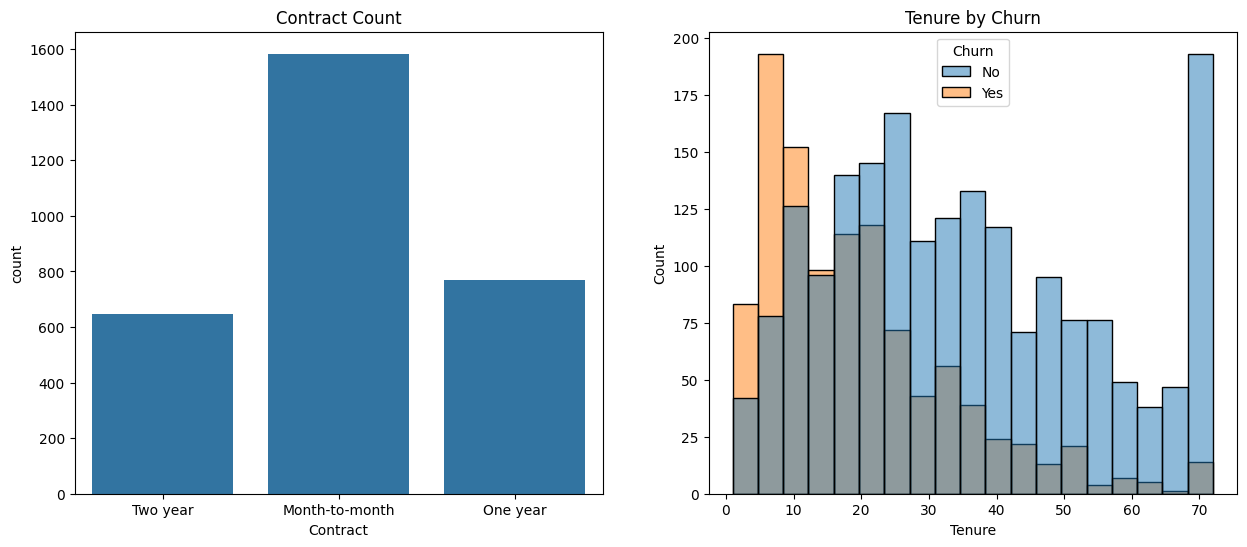

In [8]:
# 아래 코드의 빈칸을 채우고 실행하세요.
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))
sns.countplot(data=data, x='Contract', ax=axes[0])
sns.histplot(data=data, x='Tenure', hue='Churn', ax=axes[1])
axes[0].set_title('Contract Count')
axes[1].set_title('Tenure by Churn')
plt.show()

답안3_1 = 'subplots'
답안3_2 = 'hue'
답안3_3 = 'set_title'

### 4. 이탈 여부(Churn) 별 고객센터 상담 횟수(SupportCalls) 분포를 boxplot 으로 그리세요
- X축에 Churn, Y축에 SupportCalls

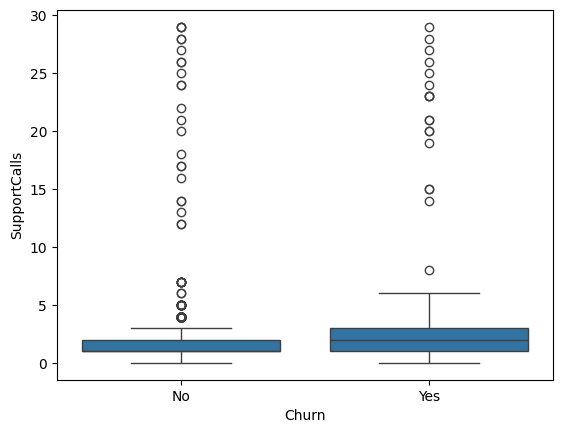

In [9]:
sns.boxplot(data=data, x='Churn', y='SupportCalls')
plt.show()

## <데이터 전처리>
### 5. SupportCalls 의 IQR 이상치가 있는 행을 삭제하고, 고객 번호(CustomerID) 컬럼을 삭제한 뒤 인덱스를 초기화하세요
- 결과는 `data_temp` 에 저장하세요.
- 빈칸에 들어갈 말을 `답안5_1`, `답안5_2` 에 저장하고, 남은 행 수를 `답안5_3` 에 저장하세요.

In [45]:
# 아래 코드의 빈칸을 채우고 실행하세요.
q1 = data['SupportCalls'].quantile(0.25)
q3 = data['SupportCalls'].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
data_temp = data.drop(data[(data['SupportCalls'] > upper_fence) | (data['SupportCalls'] < lower_fence)].index, axis=0)
data_temp = data_temp.drop(columns=['CustomerID'])
data_temp.reset_index(drop=True, inplace=True)

답안5_1 = 'drop'
답안5_2 = 'index'
답안5_3 = len(data_temp) # 남은 행 수를 구하는 건 len()

2736

### 6. 결측치 개수를 확인한 뒤 결측치가 있는 행을 모두 삭제해 `data_na` 에 저장하고, 결측치가 사라졌는지 확인하세요
- 남은 행 수를 `답안6` 에 저장하세요.

In [12]:
data_temp.isnull().sum()
data_na = data_temp.dropna()
data_na.isnull().sum()

답안6 = len(data_na)
답안6

2572

### 7. 결제 방법(PaymentMethod)을 정리하고 원 핫 인코딩하세요
- 'Card|Auto', 'Card|Manual' 2가지 값을 'Card' 로 치환
- 'Bank transfer|Auto' 1가지 값을 'Bank transfer' 로 치환
- 치환 후 PaymentMethod 의 카테고리별 개수를 출력하세요.
- 원 핫 인코딩 대상: Gender, Contract, InternetService, PaymentMethod · 결과는 `data_preset`
- 빈칸을 채우고 오류를 정정하세요. 치환 후 'Card' 의 개수를 `답안7` 에 저장하세요.

In [26]:
# 아래 코드의 빈칸을 채우고 오류를 정정하세요.
data_na = data_na.copy()
data_na.loc[data_na['PaymentMethod'].isin(['Card|Auto', 'Card|Manual']), ['PaymentMethod']] = 'Card'
data_na.loc[data_na['PaymentMethod'].isin(['Bank transfer|Auto']), ['PaymentMethod']] = 'Bank transfer'
print(data_na['PaymentMethod'].value_counts())

data_preset = pd.get_dummies(data=data_na, columns=['Gender', 'Contract', 'InternetService', 'PaymentMethod']) #get_dummies 에는 axis 옵션이 없다
data_preset.info()

답안7 = (data_na['PaymentMethod'] == 'Card').sum()
답안7

PaymentMethod
Electronic check    920
Card                621
Bank transfer       581
Mailed check        450
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
Index: 2572 entries, 0 to 2735
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Churn                           2572 non-null   object 
 1   SeniorCitizen                   2572 non-null   int64  
 2   Tenure                          2572 non-null   int64  
 3   MonthlyCharges                  2572 non-null   float64
 4   TotalCharges                    2572 non-null   float64
 5   SupportCalls                    2572 non-null   int64  
 6   Gender_Female                   2572 non-null   bool   
 7   Gender_Male                     2572 non-null   bool   
 8   Contract_Month-to-month         2572 non-null   bool   
 9   Contract_One year               2572 non-null   bool   
 10  Contract_Two year        

np.int64(621)

### 8. Churn 을 레이블 y, 나머지를 피처 X 로 하고 학습용·검증용을 나누세요
- 변수: `X_train, X_valid, y_train, y_valid` · 비율 80:20 · 이탈 비율 유지 · 난수 시드 42

In [27]:
from sklearn.model_selection import train_test_split
X = data_preset.drop('Churn', axis=1)
y = data_preset['Churn']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

### 9. 스케일링 코드에 오류가 있습니다. 정정하고, 스케일링된 검증 데이터의 최댓값을 소수 둘째 자리까지 반올림해 `답안9` 에 저장하세요
- MinMaxScaler 를 쓰세요. 변수명은 그대로 쓰세요.
- 이 셀은 X_train, X_valid 를 덮어씁니다. 고친 뒤 다시 실행할 때는 8번 셀부터 다시 실행하세요.

In [28]:
# 아래의 코드를 정정하고 실행하세요.
from sklearn.preprocessing import MinMaxScaler
mm = MinMaxScaler()
X_train = mm.fit_transform(X_train)
X_valid = mm.transform(X_valid)
답안9 = round(np.max(X_valid), 2)
답안9

np.float64(1.07)

## <AI 모델링>
### 10. DecisionTree(`gs_dt`)와 RandomForest(`gs_rf`)의 하이퍼파라미터를 GridSearchCV 로 찾으세요
- DT: max_depth [3, 5, 7], min_samples_split [2, 10, 20] · RF: n_estimators [100, 200], max_depth [3, 5], min_samples_split [2, 10]
- cv=3, scoring='accuracy', n_jobs=-1, 두 모델 모두 난수 시드 42
- RF 의 최적 max_depth 를 `답안10` 에 저장하세요.

In [46]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

gs_dt = GridSearchCV(estimator=DecisionTreeClassifier(random_state=42), param_grid={'max_depth':[3,5,7], 'min_samples_split':[2,10,20]}, cv=3, scoring='accuracy', n_jobs=-1)
gs_dt.fit(X_train, y_train)

gs_rf = GridSearchCV(estimator=RandomForestClassifier(random_state=42), param_grid={'n_estimators':[100,200], 'max_depth':[3,5], 'min_samples_split':[2,10],}, cv=3, scoring='accuracy', n_jobs=-1)
gs_rf.fit(X_train, y_train)

print(gs_rf.best_params_)

답안10 = gs_rf.best_params_['max_depth']
답안10

{'max_depth': 5, 'min_samples_split': 10, 'n_estimators': 200}


5

### 11. RandomForest 의 변수 중요도 top 5 를 막대그래프로 그리려는데 오류가 2곳 있습니다(하나는 에러 없이 결과만 틀립니다). 정정하고, 1위 피처 이름을 `답안11` 에 저장하세요

'Contract_Month-to-month'

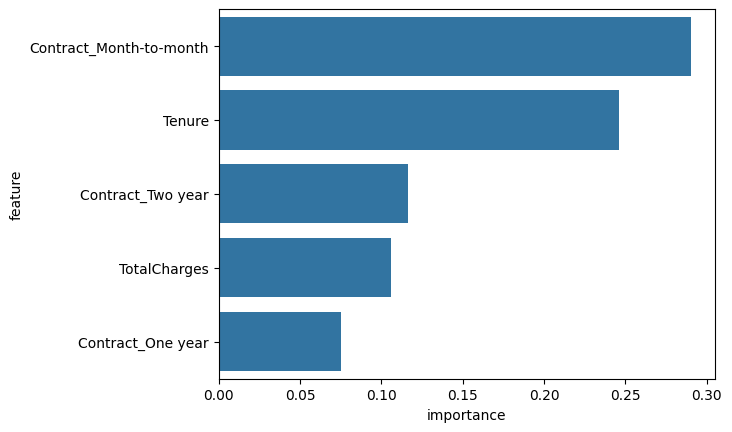

In [37]:
# 아래의 코드를 정정하고 실행하세요.
fi = pd.DataFrame({'feature': X.columns, 'importance': gs_rf.best_estimator_.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:5] # top5 를 그리니 내림차순이 되어야 함. ascending=False
sns.barplot(x='importance', y='feature', data=fi)

답안11 = fi.iloc[0]['feature']
답안11

### 12. 두 모델의 검증 정확도를 구하세요. 에러가 납니다. 정정하고, 더 우수한 모델 이름을 `답안12` 에 저장하세요 ('DecisionTree' 또는 'RandomForest')

In [39]:
# 아래의 코드를 정정하고 실행하세요.
from sklearn.metrics import accuracy_score
y_pred_dt = gs_dt.best_estimator_.predict(X_valid)
y_pred_rf = gs_rf.best_estimator_.predict(X_valid)
dt_acc = accuracy_score(y_valid, y_pred_dt)
rf_acc = accuracy_score(y_valid, y_pred_rf)
print(dt_acc, rf_acc)

답안12 = 'RandomForest' if rf_acc > dt_acc else 'DecisionTree'
답안12

0.7262135922330097 0.7572815533980582


'RandomForest'

### 다음 문항을 풀기 전에 아래 코드를 실행하세요.

In [40]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
tf.keras.utils.set_random_seed(1)

### 13. 이탈 여부를 예측하는 딥러닝 모델을 만들고 학습하세요
- 구조: Dense 64 (relu, input_dim) → Dropout 0.2 → Dense 32 (relu) → Dense 2 (sigmoid)
- y 는 LabelEncoder 로 정수로 바꾼 뒤 to_categorical 로 원 핫 · compile: adam, binary_crossentropy, accuracy
- EarlyStopping: val_loss 가 5번 나아지지 않으면 멈춤 · 학습: epochs 50, batch_size 64, 검증 데이터 지정 · 학습 정보는 `history`
- 빈칸에 들어갈 말을 `답안13_1`, `답안13_2` 에 저장하세요.
- 이 셀을 다시 실행하려면 8·9번 셀을 다시 실행한 뒤 실행하세요(y_train 이 이미 원 핫으로 바뀌어 있어요).
- 멈추는 바퀴 수는 컴퓨터마다 조금 다를 수 있어요.

In [41]:
# 아래 코드의 빈칸을 채우고 실행하세요.
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train = to_categorical(le.fit_transform(y_train))
y_valid = to_categorical(le.transform(y_valid))
model = Sequential([
    Dense(64, activation='relu', input_dim=X_train.shape[1]),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(2, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
estop = EarlyStopping(monitor='val_loss', patience=5)
history = model.fit(X_train, y_train, epochs=50, batch_size=64, validation_data=(X_valid, y_valid), callbacks=[estop])

답안13_1 = 'transform'
답안13_2 = 'patience'

Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.6417 - loss: 0.6205 - val_accuracy: 0.6466 - val_loss: 0.5672
Epoch 2/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6801 - loss: 0.5543 - val_accuracy: 0.7379 - val_loss: 0.5170
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7346 - loss: 0.5142 - val_accuracy: 0.7573 - val_loss: 0.4976
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7472 - loss: 0.5014 - val_accuracy: 0.7515 - val_loss: 0.4931
Epoch 5/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7521 - loss: 0.4980 - val_accuracy: 0.7534 - val_loss: 0.4921
Epoch 6/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7482 - loss: 0.4976 - val_accuracy: 0.7515 - val_loss: 0.4923
Epoch 7/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7487 - loss: 0.4951 - val_accuracy: 0.7534 - val_loss: 0.4922
Epoch 8/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7516 - loss: 0.4998 - val_accuracy: 0.7534 - val_loss

### 14. 학습 Loss 와 검증 Loss 의 변화를 한 그래프에 그리세요
- 범례 'loss', 'val_loss' · 제목 'Model Loss' · x축 'Epoch' · y축 'Loss'

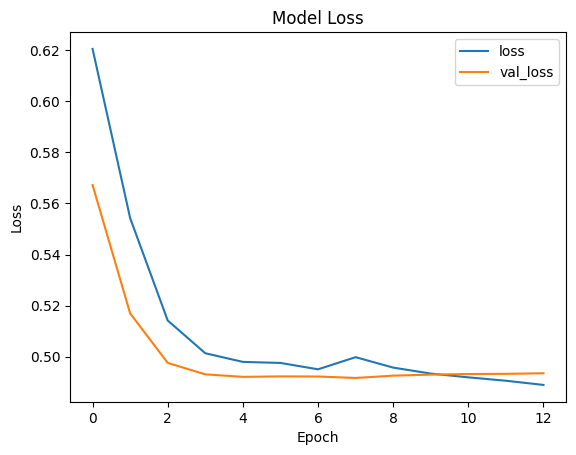

In [47]:
plt.plot(history.history['loss']) # history.history 빼먹지 않기
plt.plot(history.history['val_loss'])
plt.legend(['loss', 'val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

---
### 모든 문항이 끝났습니다.
- 해설 노트북과 영상 11편으로 채점해 보세요. 틀린 문항은 해당 회차(1~6편, 드릴 8~10편)로 돌아가 다시 보세요.